# 04 - Train and validate enrollment models
**Prerequisite:** run [03_feature_reduction.ipynb](03_feature_reduction.ipynb) with the default 15-feature selection.

Fit all three feature variants on entry cohorts **2022-2024** and evaluate on **2025 validation**. The final-evaluation section scores **2026** once per frozen model, without retraining or tuning. Each variant saves validation-specific models, metrics, forecast totals, and predictions in **results/**.

Acceptance-fee and deposit variants require later-stage information. Their scores do not establish better early-stage forecasts. This notebook changes evaluation design, not the classifier settings.

**Calendar-field revision:** notebook 03 now excludes absolute calendar years and days of the month, and keeps visit timing as years before entry. The 2026 cohort was scored once before this revision, so revised 2026 results are a follow-up comparison, not an untouched final test.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Open the notebook from the project folder. All paths are relative to it.
BASE_DIR = Path.cwd()
if not (BASE_DIR / "datathon-dataset-2026.xlsx").exists():
    raise FileNotFoundError("Open this notebook with the datathon project folder as the working directory.")
print(f"Project folder: {BASE_DIR}")
import json
from time import perf_counter

import joblib
import numpy as np
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from threadpoolctl import threadpool_limits

BASE_DIR = Path.cwd()
# cleaner.py encodes missing values in these nominal fields as -1.
FACTORIZED_COLUMNS = {"app_fee", "acceptance_fee", "residency", "sex", "college"}
DEPOSIT_FEATURES = ["deposit_dt", "deposit_mo", "deposit_yr", "deposited"]
MODEL_VARIANTS = {
    "no_acceptance_fee_no_deposits": [],
    "with_acceptance_fee_no_deposits": ["acceptance_fee"],
    "with_acceptance_fee_and_deposits": ["acceptance_fee", *DEPOSIT_FEATURES],
}



import matplotlib.pyplot as plt
summary_path = BASE_DIR / "feature_reduction_output" / "selection_summary.json"
output_dir = BASE_DIR / "results"
threshold = 0.5
if not 0 < threshold < 1:
    raise ValueError("threshold must be between 0 and 1")
reports = {}
print(f"Classification cutoff: {threshold}; outputs: {output_dir}")


Project folder: C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon
Classification cutoff: 0.5; outputs: C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\results


## 1. Define data checks, preprocessing, and evaluation
The model uses small gradient-boosted trees. Nominal category codes are treated as categories; missing numeric values and unknown categories are handled by the model. The saved pipeline includes preprocessing. All preprocessing is fitted on training data.


In [2]:
def read_table(path):
    """Read the same cleaned numeric representation used for feature selection."""
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    if path.suffix.lower() in {".xlsx", ".xlsm"}:
        return pd.read_excel(path)
    raise ValueError(f"Expected a CSV or XLSX file, received: {path}")

def add_derived_features(frame):
    """Express visit timing relative to each student's own entry year.

    Absolute calendar years do not transfer to a new cohort; years before entry do.
    Students without a recorded visit stay missing.
    """
    frame = frame.copy()
    frame["visit_yrs_before_entry"] = frame["entry_year"] - frame["visit_yr"]
    return frame

def prepare_features(frame, features):
    """Enforce feature order and normalize missing values for training/inference."""
    missing = [name for name in features if name not in frame.columns]
    if missing:
        raise ValueError(f"Missing selected feature columns: {', '.join(missing)}")
    if frame.empty:
        raise ValueError("The input contains no rows.")
    values = frame.loc[:, features].apply(pd.to_numeric, errors="raise").astype(float)
    values = values.replace([np.inf, -np.inf], np.nan)
    for name in FACTORIZED_COLUMNS.intersection(features):
        values[name] = values[name].mask(values[name].eq(-1))
    return values

def load_selection(path):
    summary = json.loads(path.read_text(encoding="utf-8"))
    features = summary.get("selected_features")
    target = summary.get("target")
    if (
        not isinstance(features, list)
        or not features
        or not all(isinstance(name, str) and name for name in features)
        or len(features) != len(set(features))
    ):
        raise ValueError("The selection summary must have unique selected_features.")
    if not isinstance(target, str) or not target:
        raise ValueError("The selection summary must specify a target column.")
    forbidden = set(summary.get("excluded_columns", {})) | {target}
    if forbidden.intersection(features):
        raise ValueError("Selected features contain the target or excluded columns.")
    return summary, features, target

def load_split(frame, features, target):
    if target not in frame:
        raise ValueError(f"Missing target column '{target}' in split.")
    labels = pd.to_numeric(frame[target], errors="raise")
    if labels.isna().any() or not labels.isin([0, 1]).all() or labels.nunique() != 2:
        raise ValueError("Each split must contain both classes, encoded as 0 and 1.")
    return frame, prepare_features(frame, features), labels.astype(int)

def prepare_splits(summary_path, input_path=None):
    """Recover additional columns only after verifying the feature-selection rows."""
    summary, original_features, target = load_selection(summary_path)
    if len(original_features) != 15:
        raise ValueError("Expected the original top 15 features; rerun notebook 03 with TOP_K = 15.")
    if set(original_features).intersection(["acceptance_fee", *DEPOSIT_FEATURES]):
        raise ValueError("The original 15 features must exclude acceptance_fee and deposit columns.")
    source = input_path if input_path is not None else Path(summary["input"])
    print(f"Reading {source} ...", flush=True)
    dataset = add_derived_features(read_table(source))
    required = original_features + ["acceptance_fee", *DEPOSIT_FEATURES, target] + ["entry_year"]
    missing = [name for name in required if name not in dataset]
    if missing:
        raise ValueError(f"Missing source columns: {', '.join(missing)}")
    if not dataset[target].dropna().isin([0, 1]).all():
        raise ValueError(f"'{target}' must contain only 0, 1, or missing values.")
    labeled = dataset.dropna(subset=[target]).reset_index(drop=True)
    splits = {
        "train": labeled.loc[(labeled['entry_year'] >= 2022) & (labeled['entry_year'] <= 2024)].reset_index(drop=True),
        "validation": labeled.loc[labeled['entry_year'] == 2025].reset_index(drop=True),
        "test": labeled.loc[labeled['entry_year'] == 2026].reset_index(drop=True),
    }
    if sum(len(frame) for frame in splits.values()) != len(labeled):
        raise ValueError("Every labeled row must belong to entry years 2022-2026.")
    for name, frame in splits.items():
        if frame.empty:
            raise ValueError(f"The {name} split is empty.")
        original = read_table(summary_path.parent / f"reduced_{name}.csv")
        try:
            pd.testing.assert_frame_equal(
                frame[original_features + [target]],
                original[original_features + [target]],
                check_dtype=False,
            )
        except AssertionError as error:
            raise ValueError(
                f"Reconstructed {name} rows do not match the original split. "
                "Use the same cleaned source data used for feature reduction."
            ) from error
        if summary.get(f"{name}_rows") != len(frame):
            raise ValueError(f"{name}_rows does not match the selection summary; regenerate the split.")
    return summary, original_features, target, splits

def build_model(features):
    """Small boosted trees capture nonlinear effects without scaling/imputation.

    Nominal codes are encoded as categorical features, without imposing an order.
    Unknown categories become missing, which the classifier handles natively.
    The encoder and classifier are saved together to preserve inference behavior.
    """
    categorical = [name for name in features if name in FACTORIZED_COLUMNS]
    numeric = [name for name in features if name not in categorical]
    transformers = [("numeric", "passthrough", numeric)]
    if categorical:
        transformers.append((
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=np.nan,
                encoded_missing_value=np.nan,
            ),
            categorical,
        ))
    return Pipeline([
        ("features", ColumnTransformer(transformers)),
        ("classifier", HistGradientBoostingClassifier(
            categorical_features=[False] * len(numeric) + [True] * len(categorical),
            learning_rate=0.1,
            max_iter=150,
            max_leaf_nodes=15,
            min_samples_leaf=30,
            l2_regularization=1.0,
            early_stopping=True,
            validation_fraction=0.1,
            random_state=42,
        )),
    ])

def evaluate(labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predictions)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(labels, probabilities)),
        "average_precision": float(average_precision_score(labels, probabilities)),
        "log_loss": float(log_loss(labels, probabilities, labels=[0, 1])),
        "brier_score": float(brier_score_loss(labels, probabilities)),
        "confusion_matrix": confusion_matrix(labels, predictions, labels=[0, 1]).tolist(),
    }

def save_predictions(frame, probabilities, threshold, output, target):
    # Row numbers are one-based data-row positions (excluding the header).
    result = pd.DataFrame({"row_number": np.arange(1, len(frame) + 1)})
    if "student_id" in frame:
        result["student_id"] = frame["student_id"].to_numpy()
    if target in frame:
        result[f"actual_{target}"] = frame[target].to_numpy()
    result["enrollment_probability"] = probabilities
    result["predicted_enrolled"] = (probabilities >= threshold).astype(int)
    output.parent.mkdir(parents=True, exist_ok=True)
    result.to_csv(output, index=False)
print("Data checks, model builder, and evaluation helpers are ready.")


Data checks, model builder, and evaluation helpers are ready.


## 2. Recover and verify the temporal splits
Reconstruct training (2022-2024), validation (2025), and reserved test (2026) rows from the cleaned source. Verify all three against notebook 03 exports before fitting. Checking split integrity does not score the reserved test cohort.


In [3]:
summary, original_features, target, splits = prepare_splits(summary_path, BASE_DIR / "cleaned_dataset.xlsx")
display(pd.DataFrame({"split": list(splits), "rows": [len(frame) for frame in splits.values()], "enrollment_rate": [frame[target].mean() for frame in splits.values()]}))
display(pd.DataFrame({"original_selected_feature": original_features}))


Reading C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\cleaned_dataset.xlsx ...


,split,rows,enrollment_rate
0,train,40745,0.341244
1,validation,14829,0.319644
2,test,13967,0.312021


,original_selected_feature
0,visit_yrs_before_entry
1,visit_mo
2,campus_visit_tot
3,act_cmpst
4,act_math
5,act_engl
6,admitted
7,residency
8,miles_from_campus
9,hs_gpa


## 3. Train and validate each version
At a cutoff of 0.5, probabilities of at least 0.5 count as predicted enrollment. Precision describes predicted enrollees; recall describes actual enrollees found. ROC AUC assesses ranking. Log loss and Brier score assess probabilities. Sum probabilities to forecast class size; a count above 0.5 is a different quantity. The prior baseline assigns everyone the training enrollment rate.

All displayed performance in this section is for **2025 validation**. Early stopping uses an internal subset of training data, not 2025 or 2026.


### A · Original 15 predictors
Output prefix: **no_acceptance_fee_no_deposits**.


In [4]:
variant = 'no_acceptance_fee_no_deposits'
additional_features = MODEL_VARIANTS[variant]
features = original_features + additional_features
_, training, train_labels = load_split(splits["train"], features, target)
validation_frame, validation_features, validation_labels = load_split(splits["validation"], features, target)
model_path = output_dir / f"{variant}_validation_model.joblib"


display(pd.DataFrame({"model_feature": features}))
print(f"Training shape: {training.shape}; validation shape: {validation_features.shape}")


,model_feature
0,visit_yrs_before_entry
1,visit_mo
2,campus_visit_tot
3,act_cmpst
4,act_math
5,act_engl
6,admitted
7,residency
8,miles_from_campus
9,hs_gpa


Training shape: (40745, 15); validation shape: (14829, 15)


#### Fit on training rows
Early stopping uses an internal subset of the 2022-2024 training data. Predict on 2025 validation after fitting; 2026 remains reserved for final testing.


In [5]:
model = build_model(features)
started = perf_counter()
# A small thread pool avoids parallelism overhead on this modest dataset.
with threadpool_limits(limits=2):
    model.fit(training, train_labels)
    fit_seconds = perf_counter() - started
    probabilities = model.predict_proba(validation_features)[:, 1]

print(f"Fitted {model.named_steps['classifier'].n_iter_} boosting iterations in {fit_seconds:.2f}s")
display(pd.Series(probabilities, name="validation_enrollment_probability").describe().to_frame())


Fitted 149 boosting iterations in 0.51s


,validation_enrollment_probability
count,14829.000000
mean,0.327203
std,0.291272
min,0.000034
25%,0.057572
50%,0.204994
75%,0.605022
max,0.953802


#### Evaluate on 2025 validation rows
Rows in the confusion matrix are actual outcomes; columns are predictions. Zero means not enrolled and one means enrolled. These are validation results, not final 2026 test metrics.


In [6]:
baseline = DummyClassifier(strategy="prior").fit(training, train_labels)
baseline_probabilities = baseline.predict_proba(validation_features)[:, 1]
metrics = evaluate(validation_labels, probabilities, threshold)
report = {
    "variant": variant,
    "original_selected_features": original_features,
    "additional_features": additional_features,
    "model": "HistGradientBoostingClassifier",
    "scikit_learn_version": sklearn.__version__,
    "selected_features": features,
    "target": target,
    "train_rows": len(training),
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "validation_rows": len(validation_features),
    "train_enrollment_rate": float(train_labels.mean()),
    "validation_enrollment_rate": float(validation_labels.mean()),
    "threshold": threshold,
    "fit_seconds": fit_seconds,
    "boosting_iterations": int(model.named_steps["classifier"].n_iter_),
    "validation_metrics": metrics,
    "prior_baseline_metrics": evaluate(validation_labels, baseline_probabilities, threshold),
    "confusion_matrix_layout": "Rows = actual [0, 1]; columns = predicted [0, 1].",
    "selection_summary": str(summary_path.resolve()),
    "split": summary.get("split"),
    "prediction_time_assumption": (
        "All selected fields must be available at prediction time. "
        f"Acceptance fee included: {'acceptance_fee' in features}; "
        f"deposit status and dates included: {'deposited' in features}."
    ),
    "evaluation_note": (
        "Feature selection and preprocessing use 2022-2024 training rows only. "
        "Early stopping uses an internal training-data validation subset. "
        "These metrics evaluate 2025 validation; 2026 is reserved for final testing. "
        "All predictors must be available at prediction time."
    ),
}

reports[variant] = report
display(pd.DataFrame({"model": {k: v for k, v in metrics.items() if k != "confusion_matrix"}, "prior_baseline": {k: v for k, v in report["prior_baseline_metrics"].items() if k != "confusion_matrix"}}))
display(pd.DataFrame(metrics["confusion_matrix"], index=["Actual: not enrolled", "Actual: enrolled"], columns=["Predicted: not enrolled", "Predicted: enrolled"]))


,model,prior_baseline
accuracy,0.784274,0.680356
balanced_accuracy,0.760032,0.500000
precision,0.653272,0.000000
recall,0.692827,0.000000
f1,0.672469,0.000000
roc_auc,0.844477,0.500000
average_precision,0.689525,0.319644
log_loss,0.449368,0.627650
brier_score,0.147846,0.217938


,Predicted: not enrolled,Predicted: enrolled
Actual: not enrolled,8346,1743
Actual: enrolled,1456,3284


In [7]:
predicted_enrollment = probabilities.sum()
actual_enrollment = validation_labels.sum()
forecast_error = predicted_enrollment - actual_enrollment
percent_error = forecast_error / actual_enrollment * 100

print(f"Predicted enrollment: {predicted_enrollment:,.1f}")
print(f"Actual enrollment: {actual_enrollment:,}")
print(f"Forecast error: {forecast_error:+,.1f} students")
print(f"Percent error: {percent_error:+.2f}%\n")

baseline_predicted_enrollment = baseline_probabilities.sum()
actual_enrollment = validation_labels.sum()
baseline_forecast_error = baseline_predicted_enrollment - actual_enrollment
baseline_percent_error = baseline_forecast_error / actual_enrollment * 100

print(f"Baseline Predicted enrollment: {baseline_predicted_enrollment:,.1f}")
print(f"Actual enrollment: {actual_enrollment:,}")
print(f"Forecast error: {baseline_forecast_error:+,.1f} students")
print(f"Percent error: {baseline_percent_error:+.2f}%")

report["validation_forecast"] = {
    "predicted_enrollment": float(predicted_enrollment),
    "actual_enrollment": int(actual_enrollment),
    "forecast_error": float(forecast_error),
    "percent_error": float(percent_error),
}
report["prior_baseline_forecast"] = {
    "predicted_enrollment": float(baseline_predicted_enrollment),
    "actual_enrollment": int(actual_enrollment),
    "forecast_error": float(baseline_forecast_error),
    "percent_error": float(baseline_percent_error),
}


Predicted enrollment: 4,852.1
Actual enrollment: 4,740
Forecast error: +112.1 students
Percent error: +2.36%

Baseline Predicted enrollment: 5,060.3
Actual enrollment: 4,740
Forecast error: +320.3 students
Percent error: +6.76%


#### Save the validation pipeline, metrics, and predictions
These validation-specific files preserve the previous artifacts. Predictions cover 2025 only; the saved model was fitted on 2022-2024.


In [8]:
output_dir.mkdir(parents=True, exist_ok=True)
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "variant": variant,
    "model": model,
    "selected_features": features,
    "target": target,
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "threshold": threshold,
    "scikit_learn_version": sklearn.__version__,
}, model_path)
(output_dir / f"{variant}_validation_metrics.json").write_text(
    json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
save_predictions(validation_frame, probabilities, threshold, output_dir / f"{variant}_validation_predictions.csv", target)

display(pd.read_csv(output_dir / f"{variant}_validation_predictions.csv").head(10))
display(pd.DataFrame({"saved_file": [model_path.name, f"{variant}_validation_metrics.json", f"{variant}_validation_predictions.csv"]}))


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,104312,0,0.000343,0
1,2,54540,0,0.000512,0
2,3,70857,0,0.000397,0
3,4,89816,0,0.127764,0
4,5,128659,0,0.000406,0
5,6,66310,0,0.000394,0
6,7,44083,0,0.463765,0
7,8,42367,0,0.000630,0
8,9,66530,0,0.000422,0
9,10,55585,0,0.000422,0


,saved_file
0,no_acceptance_fee_no_deposits_validation_model...
1,no_acceptance_fee_no_deposits_validation_metri...
2,no_acceptance_fee_no_deposits_validation_predi...


### B · Add acceptance fee
Output prefix: **with_acceptance_fee_no_deposits**.


In [9]:
variant = 'with_acceptance_fee_no_deposits'
additional_features = MODEL_VARIANTS[variant]
features = original_features + additional_features
_, training, train_labels = load_split(splits["train"], features, target)
validation_frame, validation_features, validation_labels = load_split(splits["validation"], features, target)
model_path = output_dir / f"{variant}_validation_model.joblib"


display(pd.DataFrame({"model_feature": features}))
print(f"Training shape: {training.shape}; validation shape: {validation_features.shape}")


,model_feature
0,visit_yrs_before_entry
1,visit_mo
2,campus_visit_tot
3,act_cmpst
4,act_math
5,act_engl
6,admitted
7,residency
8,miles_from_campus
9,hs_gpa


Training shape: (40745, 16); validation shape: (14829, 16)


#### Fit on training rows
Early stopping uses an internal subset of the 2022-2024 training data. Predict on 2025 validation after fitting; 2026 remains reserved for final testing.


In [10]:
model = build_model(features)
started = perf_counter()
# A small thread pool avoids parallelism overhead on this modest dataset.
with threadpool_limits(limits=2):
    model.fit(training, train_labels)
    fit_seconds = perf_counter() - started
    probabilities = model.predict_proba(validation_features)[:, 1]

print(f"Fitted {model.named_steps['classifier'].n_iter_} boosting iterations in {fit_seconds:.2f}s")
display(pd.Series(probabilities, name="validation_enrollment_probability").describe().to_frame())


Fitted 110 boosting iterations in 0.34s


,validation_enrollment_probability
count,14829.000000
mean,0.275626
std,0.396528
min,0.000018
25%,0.001759
50%,0.003581
75%,0.800744
max,0.988878


#### Evaluate on 2025 validation rows
Rows in the confusion matrix are actual outcomes; columns are predictions. Zero means not enrolled and one means enrolled. These are validation results, not final 2026 test metrics.


In [11]:
baseline = DummyClassifier(strategy="prior").fit(training, train_labels)
baseline_probabilities = baseline.predict_proba(validation_features)[:, 1]
metrics = evaluate(validation_labels, probabilities, threshold)
report = {
    "variant": variant,
    "original_selected_features": original_features,
    "additional_features": additional_features,
    "model": "HistGradientBoostingClassifier",
    "scikit_learn_version": sklearn.__version__,
    "selected_features": features,
    "target": target,
    "train_rows": len(training),
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "validation_rows": len(validation_features),
    "train_enrollment_rate": float(train_labels.mean()),
    "validation_enrollment_rate": float(validation_labels.mean()),
    "threshold": threshold,
    "fit_seconds": fit_seconds,
    "boosting_iterations": int(model.named_steps["classifier"].n_iter_),
    "validation_metrics": metrics,
    "prior_baseline_metrics": evaluate(validation_labels, baseline_probabilities, threshold),
    "confusion_matrix_layout": "Rows = actual [0, 1]; columns = predicted [0, 1].",
    "selection_summary": str(summary_path.resolve()),
    "split": summary.get("split"),
    "prediction_time_assumption": (
        "All selected fields must be available at prediction time. "
        f"Acceptance fee included: {'acceptance_fee' in features}; "
        f"deposit status and dates included: {'deposited' in features}."
    ),
    "evaluation_note": (
        "Feature selection and preprocessing use 2022-2024 training rows only. "
        "Early stopping uses an internal training-data validation subset. "
        "These metrics evaluate 2025 validation; 2026 is reserved for final testing. "
        "All predictors must be available at prediction time."
    ),
}

reports[variant] = report
display(pd.DataFrame({"model": {k: v for k, v in metrics.items() if k != "confusion_matrix"}, "prior_baseline": {k: v for k, v in report["prior_baseline_metrics"].items() if k != "confusion_matrix"}}))
display(pd.DataFrame(metrics["confusion_matrix"], index=["Actual: not enrolled", "Actual: enrolled"], columns=["Predicted: not enrolled", "Predicted: enrolled"]))


,model,prior_baseline
accuracy,0.974644,0.680356
balanced_accuracy,0.968111,0.500000
precision,0.970056,0.000000
recall,0.950000,0.000000
f1,0.959923,0.000000
roc_auc,0.993737,0.500000
average_precision,0.976444,0.319644
log_loss,0.088031,0.627650
brier_score,0.022351,0.217938


,Predicted: not enrolled,Predicted: enrolled
Actual: not enrolled,9950,139
Actual: enrolled,237,4503


In [12]:
predicted_enrollment = probabilities.sum()
actual_enrollment = validation_labels.sum()
forecast_error = predicted_enrollment - actual_enrollment
percent_error = forecast_error / actual_enrollment * 100

print(f"Predicted enrollment: {predicted_enrollment:,.1f}")
print(f"Actual enrollment: {actual_enrollment:,}")
print(f"Forecast error: {forecast_error:+,.1f} students")
print(f"Percent error: {percent_error:+.2f}%\n")

baseline_predicted_enrollment = baseline_probabilities.sum()
actual_enrollment = validation_labels.sum()
baseline_forecast_error = baseline_predicted_enrollment - actual_enrollment
baseline_percent_error = baseline_forecast_error / actual_enrollment * 100

print(f"Baseline Predicted enrollment: {baseline_predicted_enrollment:,.1f}")
print(f"Actual enrollment: {actual_enrollment:,}")
print(f"Forecast error: {baseline_forecast_error:+,.1f} students")
print(f"Percent error: {baseline_percent_error:+.2f}%")

report["validation_forecast"] = {
    "predicted_enrollment": float(predicted_enrollment),
    "actual_enrollment": int(actual_enrollment),
    "forecast_error": float(forecast_error),
    "percent_error": float(percent_error),
}
report["prior_baseline_forecast"] = {
    "predicted_enrollment": float(baseline_predicted_enrollment),
    "actual_enrollment": int(actual_enrollment),
    "forecast_error": float(baseline_forecast_error),
    "percent_error": float(baseline_percent_error),
}


Predicted enrollment: 4,087.3
Actual enrollment: 4,740
Forecast error: -652.7 students
Percent error: -13.77%

Baseline Predicted enrollment: 5,060.3
Actual enrollment: 4,740
Forecast error: +320.3 students
Percent error: +6.76%


#### Save the validation pipeline, metrics, and predictions
These validation-specific files preserve the previous artifacts. Predictions cover 2025 only; the saved model was fitted on 2022-2024.


In [13]:
output_dir.mkdir(parents=True, exist_ok=True)
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "variant": variant,
    "model": model,
    "selected_features": features,
    "target": target,
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "threshold": threshold,
    "scikit_learn_version": sklearn.__version__,
}, model_path)
(output_dir / f"{variant}_validation_metrics.json").write_text(
    json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
save_predictions(validation_frame, probabilities, threshold, output_dir / f"{variant}_validation_predictions.csv", target)

display(pd.read_csv(output_dir / f"{variant}_validation_predictions.csv").head(10))
display(pd.DataFrame({"saved_file": [model_path.name, f"{variant}_validation_metrics.json", f"{variant}_validation_predictions.csv"]}))


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,104312,0,0.000072,0
1,2,54540,0,0.000097,0
2,3,70857,0,0.000097,0
3,4,89816,0,0.005108,0
4,5,128659,0,0.000061,0
5,6,66310,0,0.000073,0
6,7,44083,0,0.047573,0
7,8,42367,0,0.000106,0
8,9,66530,0,0.000100,0
9,10,55585,0,0.000081,0


,saved_file
0,with_acceptance_fee_no_deposits_validation_mod...
1,with_acceptance_fee_no_deposits_validation_met...
2,with_acceptance_fee_no_deposits_validation_pre...


### C · Add acceptance fee and deposit fields
Output prefix: **with_acceptance_fee_and_deposits**.


In [14]:
variant = 'with_acceptance_fee_and_deposits'
additional_features = MODEL_VARIANTS[variant]
features = original_features + additional_features
_, training, train_labels = load_split(splits["train"], features, target)
validation_frame, validation_features, validation_labels = load_split(splits["validation"], features, target)
model_path = output_dir / f"{variant}_validation_model.joblib"


display(pd.DataFrame({"model_feature": features}))
print(f"Training shape: {training.shape}; validation shape: {validation_features.shape}")


,model_feature
0,visit_yrs_before_entry
1,visit_mo
2,campus_visit_tot
3,act_cmpst
4,act_math
5,act_engl
6,admitted
7,residency
8,miles_from_campus
9,hs_gpa


Training shape: (40745, 20); validation shape: (14829, 20)


#### Fit on training rows
Early stopping uses an internal subset of the 2022-2024 training data. Predict on 2025 validation after fitting; 2026 remains reserved for final testing.


In [15]:
model = build_model(features)
started = perf_counter()
# A small thread pool avoids parallelism overhead on this modest dataset.
with threadpool_limits(limits=2):
    model.fit(training, train_labels)
    fit_seconds = perf_counter() - started
    probabilities = model.predict_proba(validation_features)[:, 1]

print(f"Fitted {model.named_steps['classifier'].n_iter_} boosting iterations in {fit_seconds:.2f}s")
display(pd.Series(probabilities, name="validation_enrollment_probability").describe().to_frame())


Fitted 77 boosting iterations in 0.25s


,validation_enrollment_probability
count,14829.000000
mean,0.321165
std,0.464164
min,0.000195
25%,0.000195
50%,0.000195
75%,0.992833
max,0.999044


#### Evaluate on 2025 validation rows
Rows in the confusion matrix are actual outcomes; columns are predictions. Zero means not enrolled and one means enrolled. These are validation results, not final 2026 test metrics.


In [16]:
baseline = DummyClassifier(strategy="prior").fit(training, train_labels)
baseline_probabilities = baseline.predict_proba(validation_features)[:, 1]
metrics = evaluate(validation_labels, probabilities, threshold)
report = {
    "variant": variant,
    "original_selected_features": original_features,
    "additional_features": additional_features,
    "model": "HistGradientBoostingClassifier",
    "scikit_learn_version": sklearn.__version__,
    "selected_features": features,
    "target": target,
    "train_rows": len(training),
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "validation_rows": len(validation_features),
    "train_enrollment_rate": float(train_labels.mean()),
    "validation_enrollment_rate": float(validation_labels.mean()),
    "threshold": threshold,
    "fit_seconds": fit_seconds,
    "boosting_iterations": int(model.named_steps["classifier"].n_iter_),
    "validation_metrics": metrics,
    "prior_baseline_metrics": evaluate(validation_labels, baseline_probabilities, threshold),
    "confusion_matrix_layout": "Rows = actual [0, 1]; columns = predicted [0, 1].",
    "selection_summary": str(summary_path.resolve()),
    "split": summary.get("split"),
    "prediction_time_assumption": (
        "All selected fields must be available at prediction time. "
        f"Acceptance fee included: {'acceptance_fee' in features}; "
        f"deposit status and dates included: {'deposited' in features}."
    ),
    "evaluation_note": (
        "Feature selection and preprocessing use 2022-2024 training rows only. "
        "Early stopping uses an internal training-data validation subset. "
        "These metrics evaluate 2025 validation; 2026 is reserved for final testing. "
        "All predictors must be available at prediction time."
    ),
}

reports[variant] = report
display(pd.DataFrame({"model": {k: v for k, v in metrics.items() if k != "confusion_matrix"}, "prior_baseline": {k: v for k, v in report["prior_baseline_metrics"].items() if k != "confusion_matrix"}}))
display(pd.DataFrame(metrics["confusion_matrix"], index=["Actual: not enrolled", "Actual: enrolled"], columns=["Predicted: not enrolled", "Predicted: enrolled"]))


,model,prior_baseline
accuracy,0.996021,0.680356
balanced_accuracy,0.997076,0.500000
precision,0.987706,0.000000
recall,1.000000,0.000000
f1,0.993815,0.000000
roc_auc,0.998170,0.500000
average_precision,0.993778,0.319644
log_loss,0.021470,0.627650
brier_score,0.003899,0.217938


,Predicted: not enrolled,Predicted: enrolled
Actual: not enrolled,10030,59
Actual: enrolled,0,4740


In [17]:
predicted_enrollment = probabilities.sum()
actual_enrollment = validation_labels.sum()
forecast_error = predicted_enrollment - actual_enrollment
percent_error = forecast_error / actual_enrollment * 100

print(f"Predicted enrollment: {predicted_enrollment:,.1f}")
print(f"Actual enrollment: {actual_enrollment:,}")
print(f"Forecast error: {forecast_error:+,.1f} students")
print(f"Percent error: {percent_error:+.2f}%\n")

baseline_predicted_enrollment = baseline_probabilities.sum()
actual_enrollment = validation_labels.sum()
baseline_forecast_error = baseline_predicted_enrollment - actual_enrollment
baseline_percent_error = baseline_forecast_error / actual_enrollment * 100

print(f"Baseline Predicted enrollment: {baseline_predicted_enrollment:,.1f}")
print(f"Actual enrollment: {actual_enrollment:,}")
print(f"Forecast error: {baseline_forecast_error:+,.1f} students")
print(f"Percent error: {baseline_percent_error:+.2f}%")

report["validation_forecast"] = {
    "predicted_enrollment": float(predicted_enrollment),
    "actual_enrollment": int(actual_enrollment),
    "forecast_error": float(forecast_error),
    "percent_error": float(percent_error),
}
report["prior_baseline_forecast"] = {
    "predicted_enrollment": float(baseline_predicted_enrollment),
    "actual_enrollment": int(actual_enrollment),
    "forecast_error": float(baseline_forecast_error),
    "percent_error": float(baseline_percent_error),
}


Predicted enrollment: 4,762.6
Actual enrollment: 4,740
Forecast error: +22.6 students
Percent error: +0.48%

Baseline Predicted enrollment: 5,060.3
Actual enrollment: 4,740
Forecast error: +320.3 students
Percent error: +6.76%


#### Save the validation pipeline, metrics, and predictions
These validation-specific files preserve the previous artifacts. Predictions cover 2025 only; the saved model was fitted on 2022-2024.


In [18]:
output_dir.mkdir(parents=True, exist_ok=True)
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({
    "variant": variant,
    "model": model,
    "selected_features": features,
    "target": target,
    "training_entry_years": [2022, 2023, 2024],
    "validation_entry_year": 2025,
    "reserved_test_entry_year": 2026,
    "threshold": threshold,
    "scikit_learn_version": sklearn.__version__,
}, model_path)
(output_dir / f"{variant}_validation_metrics.json").write_text(
    json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
save_predictions(validation_frame, probabilities, threshold, output_dir / f"{variant}_validation_predictions.csv", target)

display(pd.read_csv(output_dir / f"{variant}_validation_predictions.csv").head(10))
display(pd.DataFrame({"saved_file": [model_path.name, f"{variant}_validation_metrics.json", f"{variant}_validation_predictions.csv"]}))


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,104312,0,0.000195,0
1,2,54540,0,0.000195,0
2,3,70857,0,0.000195,0
3,4,89816,0,0.000195,0
4,5,128659,0,0.000195,0
5,6,66310,0,0.000195,0
6,7,44083,0,0.000195,0
7,8,42367,0,0.000195,0
8,9,66530,0,0.000195,0
9,10,55585,0,0.000195,0


,saved_file
0,with_acceptance_fee_and_deposits_validation_mo...
1,with_acceptance_fee_and_deposits_validation_me...
2,with_acceptance_fee_and_deposits_validation_pr...


## 4. Compare 2025 validation results
All variants use the same training and validation students but different information availability. Compare model discrimination, probability quality, and class-size error separately. These are not final 2026 test results and do not establish causal effects.


,feature_count,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,log_loss,brier_score,predicted_enrollment,actual_enrollment,forecast_error,percent_error,baseline_predicted_enrollment,baseline_forecast_error,baseline_percent_error
variant,,,,,,,,,,,,,,,,,
no_acceptance_fee_no_deposits,15,0.784274,0.760032,0.653272,0.692827,0.672469,0.844477,0.689525,0.449368,0.147846,4852.087189,4740,112.087189,2.364709,5060.312087,320.312087,6.757639
with_acceptance_fee_no_deposits,16,0.974644,0.968111,0.970056,0.950000,0.959923,0.993737,0.976444,0.088031,0.022351,4087.265024,4740,-652.734976,-13.770780,5060.312087,320.312087,6.757639
with_acceptance_fee_and_deposits,20,0.996021,0.997076,0.987706,1.000000,0.993815,0.998170,0.993778,0.021470,0.003899,4762.556214,4740,22.556214,0.475869,5060.312087,320.312087,6.757639


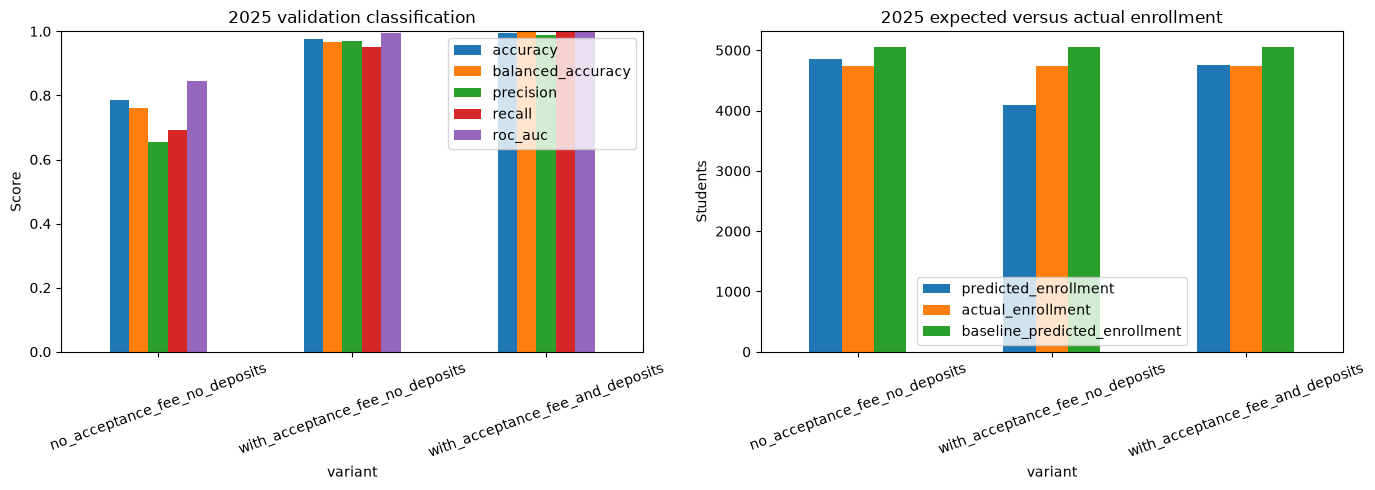

Saved validation comparison table and chart to C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\results


In [19]:
comparison = pd.DataFrame([
    {
        "variant": name,
        "feature_count": len(report["selected_features"]),
        **{key: value for key, value in report["validation_metrics"].items() if key != "confusion_matrix"},
        **report["validation_forecast"],
        "baseline_predicted_enrollment": report["prior_baseline_forecast"]["predicted_enrollment"],
        "baseline_forecast_error": report["prior_baseline_forecast"]["forecast_error"],
        "baseline_percent_error": report["prior_baseline_forecast"]["percent_error"],
    }
    for name, report in reports.items()
]).set_index("variant")
comparison.to_csv(output_dir / "validation_model_comparison.csv")
display(comparison)
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
comparison[["accuracy", "balanced_accuracy", "precision", "recall", "roc_auc"]].plot.bar(ax=axes[0])
axes[0].set(ylim=(0, 1), ylabel="Score", title="2025 validation classification")
comparison[["predicted_enrollment", "actual_enrollment", "baseline_predicted_enrollment"]].plot.bar(ax=axes[1])
axes[1].set(ylim=(0, None), ylabel="Students", title="2025 expected versus actual enrollment")
for axis in axes:
    axis.tick_params(axis="x", labelrotation=20)
figure.tight_layout()
figure.savefig(output_dir / "validation_model_comparison.png", dpi=180)
display(figure)
plt.close(figure)
print(f"Saved validation comparison table and chart to {output_dir}")


## 5. Final evaluation on 2026
Freeze all three fitted variants before running this section. Load the saved training-only models and evaluate each once on the 2026 cohort; do not tune settings or thresholds using these results. These 2026 results follow the calendar-field revision, which was made after a first 2026 evaluation, so they are a revised comparison rather than an untouched test. Validation remains separate. Different information stages are not interchangeable forecasts.


In [20]:
final_results = []
for variant in MODEL_VARIANTS:
    artifact = joblib.load(output_dir / f"{variant}_validation_model.joblib")
    test_frame, test_features, test_labels = load_split(
        splits["test"], artifact["selected_features"], artifact["target"]
    )
    with threadpool_limits(limits=2):
        test_probabilities = artifact["model"].predict_proba(test_features)[:, 1]
    test_metrics = evaluate(test_labels, test_probabilities, artifact["threshold"])
    predicted_enrollment = float(test_probabilities.sum())
    actual_enrollment = int(test_labels.sum())
    forecast_error = predicted_enrollment - actual_enrollment
    baseline_enrollment = float(splits["train"][target].mean() * len(test_labels))
    final_results.append({
        "variant": variant,
        "feature_count": len(artifact["selected_features"]),
        "test_entry_year": 2026,
        "test_rows": len(test_labels),
        **{key: value for key, value in test_metrics.items() if key != "confusion_matrix"},
        "predicted_enrollment": predicted_enrollment,
        "actual_enrollment": actual_enrollment,
        "forecast_error": forecast_error,
        "percent_error": forecast_error / actual_enrollment * 100,
        "baseline_predicted_enrollment": baseline_enrollment,
        "baseline_forecast_error": baseline_enrollment - actual_enrollment,
        "baseline_percent_error": (baseline_enrollment - actual_enrollment) / actual_enrollment * 100,
    })
    save_predictions(
        test_frame, test_probabilities, artifact["threshold"],
        output_dir / f"{variant}_final_test_predictions.csv", artifact["target"]
    )
final_comparison = pd.DataFrame(final_results).set_index("variant")
final_comparison.to_csv(output_dir / "final_test_comparison.csv")
display(final_comparison)


,feature_count,test_entry_year,test_rows,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,log_loss,brier_score,predicted_enrollment,actual_enrollment,forecast_error,percent_error,baseline_predicted_enrollment,baseline_forecast_error,baseline_percent_error
variant,,,,,,,,,,,,,,,,,,,
no_acceptance_fee_no_deposits,15,2026,13967,0.786712,0.764298,0.644762,0.704681,0.673391,0.859092,0.713252,0.425293,0.140605,4611.037425,4358,253.037425,5.806274,4766.15948,408.15948,9.365752
with_acceptance_fee_no_deposits,16,2026,13967,0.984392,0.982387,0.973035,0.977054,0.975040,0.994682,0.978885,0.074970,0.017118,3827.442398,4358,-530.557602,-12.174337,4766.15948,408.15948,9.365752
with_acceptance_fee_and_deposits,20,2026,13967,0.996277,0.997294,0.988209,1.000000,0.994069,0.998256,0.993280,0.020728,0.003693,4380.585777,4358,22.585777,0.518260,4766.15948,408.15948,9.365752


## 6. Inspect the 15-feature validation report
Reload the report generated in section A. All metrics and forecast totals are for 2025 validation.


In [21]:
report_path = output_dir / "no_acceptance_fee_no_deposits_validation_metrics.json"
saved_report = json.loads(report_path.read_text(encoding="utf-8"))
display(pd.Series(saved_report, dtype=object).to_frame("saved_report"))
print(f"Complete report: {report_path}")


,saved_report
variant,no_acceptance_fee_no_deposits
original_selected_features,"[visit_yrs_before_entry, visit_mo, campus_visi..."
additional_features,[]
model,HistGradientBoostingClassifier
scikit_learn_version,1.9.1
selected_features,"[visit_yrs_before_entry, visit_mo, campus_visi..."
target,enrolled
train_rows,40745
training_entry_years,"[2022, 2023, 2024]"
validation_entry_year,2025


Complete report: C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\results\no_acceptance_fee_no_deposits_validation_metrics.json


## 7. Reuse the saved validation model
Reload the first model and score a small preview of **2025 validation rows** with its stored preprocessing. This preview uses validation rows rather than rescoring the final-test cohort. New students must use the same category mappings as notebook 01.


In [22]:
artifact = joblib.load(output_dir / "no_acceptance_fee_no_deposits_validation_model.joblib")
preview = splits["validation"].head(10).copy()
values = prepare_features(preview, artifact["selected_features"])
with threadpool_limits(limits=2):
    preview_probabilities = artifact["model"].predict_proba(values)[:, 1]
preview_path = output_dir / "reloaded_validation_model_preview_predictions.csv"
save_predictions(preview, preview_probabilities, artifact["threshold"], preview_path, artifact["target"])
display(pd.read_csv(preview_path))
print(f"Saved: {preview_path}")


,row_number,student_id,actual_enrolled,enrollment_probability,predicted_enrolled
0,1,104312,0,0.000343,0
1,2,54540,0,0.000512,0
2,3,70857,0,0.000397,0
3,4,89816,0,0.127764,0
4,5,128659,0,0.000406,0
5,6,66310,0,0.000394,0
6,7,44083,0,0.463765,0
7,8,42367,0,0.000630,0
8,9,66530,0,0.000422,0
9,10,55585,0,0.000422,0


Saved: C:\Users\marks\.workspace\school\.DATA4890\datathon\datathon\results\reloaded_validation_model_preview_predictions.csv
